# Лабораторная работа №1 — вариант 4
## kNN + Softmax на MNIST 28×28

[Исходное задание](https://github.com/JustHawker/AIT_Course_SamU_2026/blob/main/lab_1-2/assignment1.ipynb), ветка `main`.

Вариант 4 по условию: **задания 1 и 3 на наборе MNIST**. В ноутбуке выполнены:
- раздел 1: kNN, пункты 1.1–1.11;
- раздел 3: softmax-классификатор, пункты 3.1–3.10.

В комплект включены только материалы варианта 4. Используется фиксированная стратифицированная подвыборка настоящего MNIST: 5000 train, 1000 validation, 1000 test, изображения 28×28.

In [1]:
import json
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
if not (ROOT / "scripts/classifiers").is_dir():
    raise RuntimeError("Откройте ноутбук из каталога lr1_classification")

from scripts.data_utils import load_dataset
from scripts.classifiers import KNearestNeighbor, Softmax
from scripts.classifiers.softmax import softmax_loss_naive, softmax_loss_vectorized
from scripts.gradient_check import grad_check_sparse
from experiments import run_experiment
get_ipython().run_line_magic("matplotlib", "inline")

DATASET = "mnist"
RECOMPUTE = False
OUT = ROOT / "outputs" / DATASET
random.seed(42)
np.random.seed(42)
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.2})

### Воспроизводимость запуска

По умолчанию используются включённые результаты реально выполненного эксперимента.
Если `summary.json` отсутствует, эксперимент запускается автоматически. `RECOMPUTE=True`
повторяет kNN и softmax и перезаписывает результаты. Test не участвует в подборе параметров:
для kNN параметр `k` выбирается по пятиблочной кросс-валидации только на train,
для softmax learning rate и L2 выбираются по validation.

In [2]:
summary_path = OUT / "summary.json"
if RECOMPUTE or not summary_path.exists():
    summary = run_experiment(DATASET)
else:
    summary = json.loads(summary_path.read_text(encoding="utf-8"))
assert summary["status"] == "completed"
print("Набор:", DATASET)
print("Фактическое время эксперимента, с:", round(summary["elapsed_seconds"], 2))
display(pd.DataFrame([summary["config"]]).T.rename(columns={0: "Значение"}))

Набор: mnist
Фактическое время эксперимента, с: 11.32


,Значение
seed,42
k_choices,"[1, 3, 5, 7, 9, 11, 15]"
cv_folds,5
learning_rates,"[0.01, 0.05, 0.1]"
regularization_strengths,"[0.0001, 0.001]"
num_iters,600
batch_size,128
blas_threads,2


## 1. Метод k ближайших соседей
### 1.1. Получение данных

Используется фиксированная стратифицированная выборка из настоящего MNIST: 5000 train, 1000 validation, 1000 test; изображения 28×28. Test взят из официальной тестовой части. load_digits в исходном примере возвращает другой набор 8×8; его отдельное воспроизведение находится в assignment1.ipynb.

Изображения загружаются в исходной размерности и диапазоне. Преобразования выполняются
в новых массивах, поэтому повторный запуск ячеек не вычитает среднее несколько раз.
Исходные идентификаторы и происхождение разбиений указаны в `data/SOURCES.md` и метаданных данных.

In [3]:
data = load_dataset(DATASET)
image_shape = tuple(data["image_shape"])
pixel_max = float(data["pixel_max"])
class_names = list(data["class_names"])
raw_images = {split: np.asarray(data[f"X_{split}"]) for split in ("train", "val", "test")}
labels = {split: np.asarray(data[f"y_{split}"]) for split in ("train", "val", "test")}
print("Форма одного изображения:", image_shape)
print("Максимум шкалы пикселя:", pixel_max)
print("Классы:", class_names)
display(pd.DataFrame([
    {"split": split, "images": str(raw_images[split].shape),
     "labels": str(labels[split].shape), "dtype": str(raw_images[split].dtype)}
    for split in raw_images
]))

Форма одного изображения: (28, 28)
Максимум шкалы пикселя: 255.0
Классы: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


,split,images,labels,dtype
0,train,"(5000, 28, 28)","(5000,)",uint8
1,val,"(1000, 28, 28)","(1000,)",uint8
2,test,"(1000, 28, 28)","(1000,)",uint8


### 1.2. Примеры каждого класса

На рисунке показаны примеры из train. Изображения сохранены при выполнении эксперимента;
их исходные классы известны из меток. Test для подбора примеров обучения не используется.

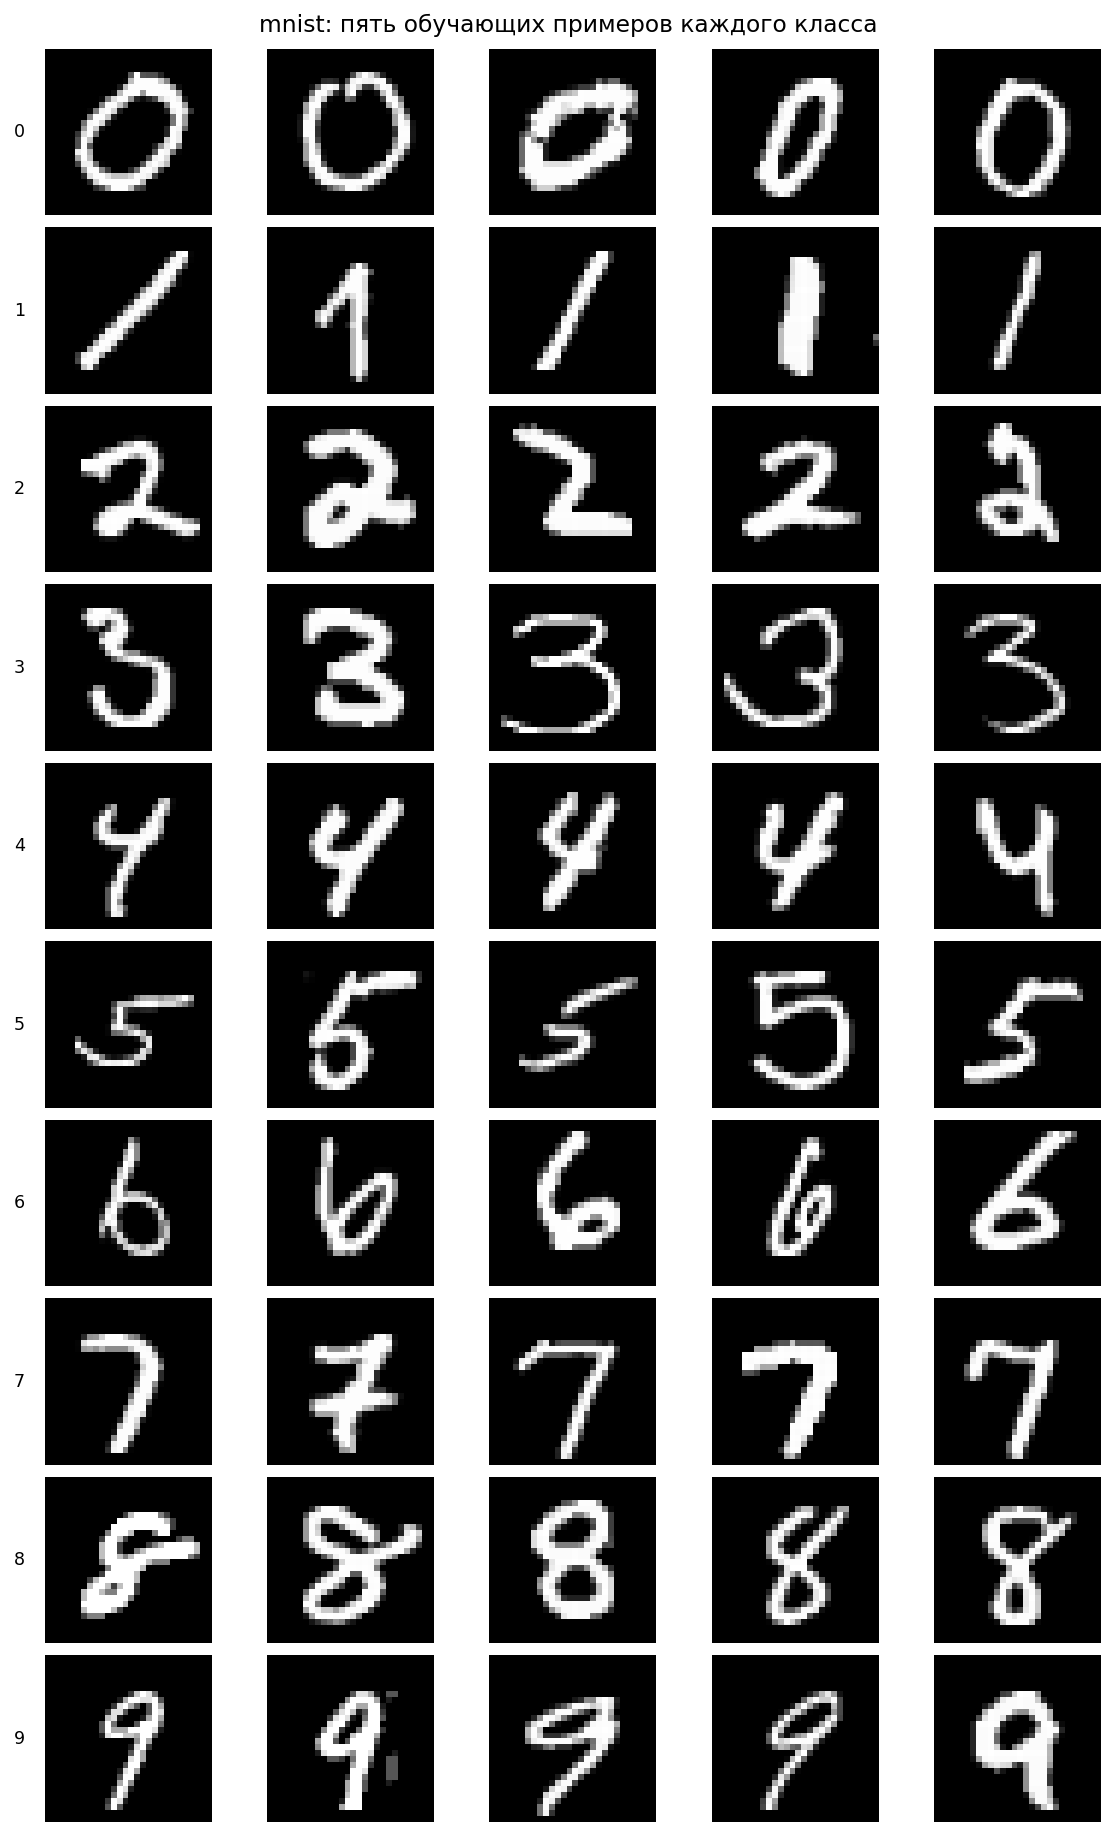

In [4]:
display(Image(filename=str(OUT / "figures/examples.png")))

### 1.3. Разбиение и преобразование в векторы

Разбиение зафиксировано в подготовленных данных. Validation используется далее для softmax.
Для kNN изображения преобразуются в одномерные векторы, а значения пикселей делятся на 255.
Одинаковое масштабирование всех признаков не меняет порядок евклидовых расстояний.

In [5]:
flat_raw = {split: raw_images[split].reshape(len(raw_images[split]), -1) for split in raw_images}
knn_features = {split: flat_raw[split].astype(np.float64) / pixel_max for split in flat_raw}
display(pd.DataFrame([
    {"split": split, "N": len(labels[split]), "D": knn_features[split].shape[1],
     "classes": len(np.unique(labels[split]))}
    for split in knn_features
]))

,split,N,D,classes
0,train,5000,784,10
1,val,1000,784,10
2,test,1000,784,10


### 1.4. Реализация и обучение kNN

Обучение kNN запоминает train. Реализованы расстояния с двумя циклами, одним циклом
и без циклов по изображениям. Векторизованная формула:
`distance² = sum(x²) + sum(t²) - 2*x@t`.
Возможные небольшие отрицательные результаты округления заменяются нулём перед корнем.
При равенстве голосов выбирается меньшая метка; при равенстве расстояний сохраняется
исходный порядок строк train.

In [6]:
probe = KNearestNeighbor()
probe.train(knn_features["train"][:6], labels["train"][:6])
distance_two = probe.compute_distances_two_loops(knn_features["test"][:3])
distance_one = probe.compute_distances_one_loop(knn_features["test"][:3])
distance_vectorized = probe.compute_distances_no_loops(knn_features["test"][:3])
np.testing.assert_allclose(distance_two, distance_one, rtol=1e-10, atol=1e-10)
np.testing.assert_allclose(distance_two, distance_vectorized, rtol=1e-10, atol=1e-10)
display(pd.DataFrame(distance_vectorized))
knn = KNearestNeighbor()
knn.train(knn_features["train"], labels["train"])
print("kNN запомнил", len(labels["train"]), "обучающих изображений")

,0,1,2,3,4,5
0,11.629232,11.720793,11.410540,10.602299,11.682539,11.819750
1,9.047266,9.743912,11.329857,9.500384,10.316028,10.103480
2,10.955844,9.347114,10.483106,9.226702,10.454430,9.957108


kNN запомнил 5000 обучающих изображений


### 1.5 и 1.7. Классификация и accuracy

Начальная модель использует k=1. Accuracy — доля совпадений предсказанных и истинных меток.
Для наглядности повторяем предсказание первых 100 test-примеров. Полная тестовая оценка
ниже берётся из завершённого эксперимента и явно отделена от проверки этой подвыборки.

In [7]:
preview_n = min(100, len(labels["test"]))
baseline_pred = knn.predict(knn_features["test"][:preview_n], k=1, batch_size=100)
print("Accuracy k=1 на первых", preview_n, "test:", np.mean(baseline_pred == labels["test"][:preview_n]))
display(pd.DataFrame([summary["knn"]["baseline"]], index=["kNN baseline, полные разбиения"]))

Accuracy k=1 на первых 100 test: 0.95


,k,train_accuracy,val_accuracy,test_accuracy
"kNN baseline, полные разбиения",1,1.0,0.944,0.924


### 1.6. Матрица расстояний test → train

Строки соответствуют изображениям test, столбцы — изображениям train.
Цвет показывает евклидово расстояние нормализованных пиксельных векторов.
Матрица построена по всем использованным изображениям, а не по трём примерам выше.

Размер полной матрицы: [1000, 5000]


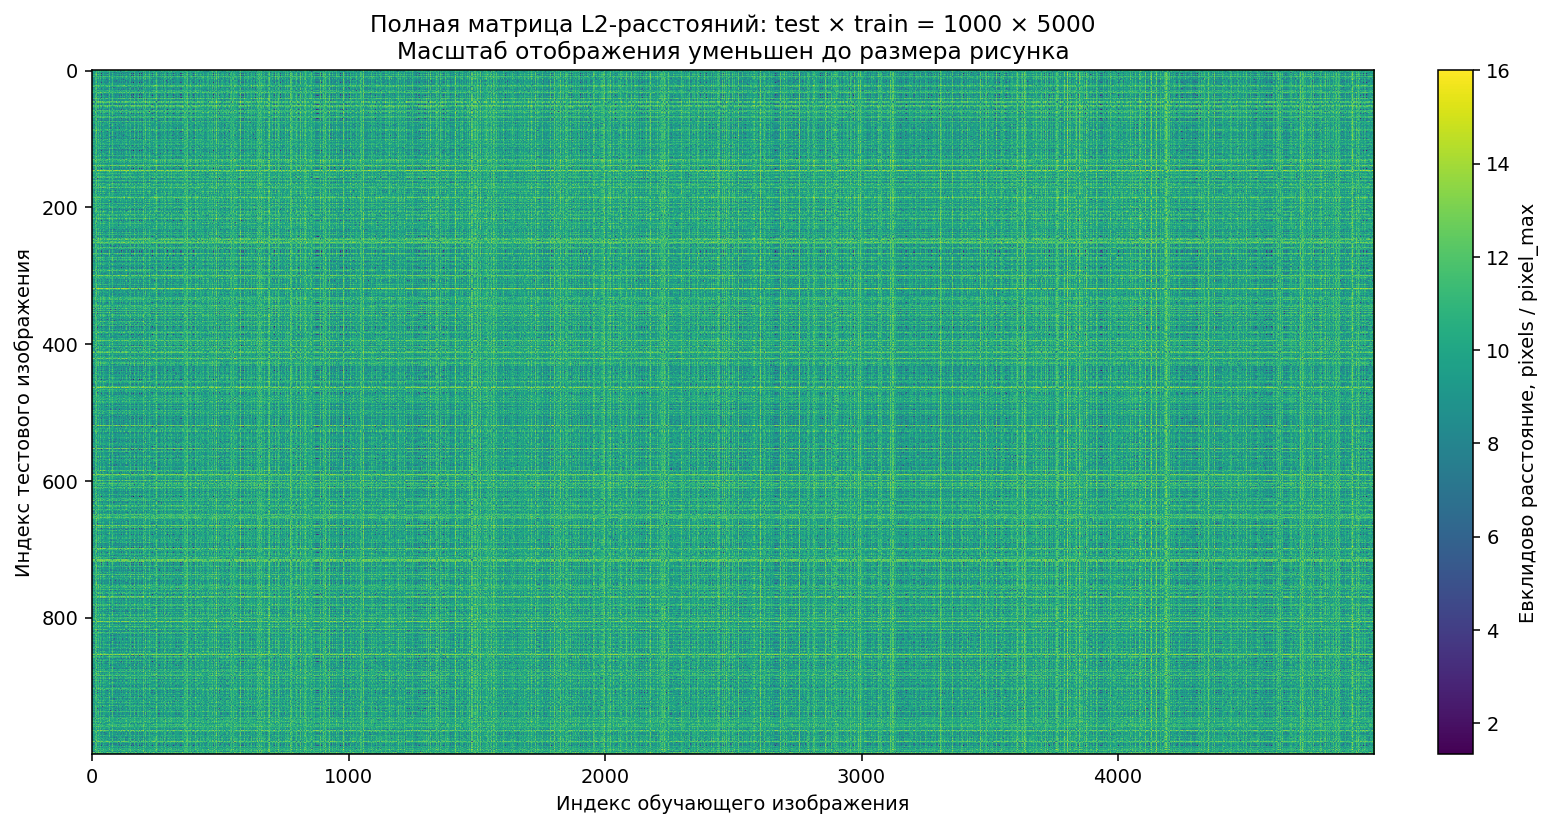

In [8]:
print("Размер полной матрицы:", summary["knn"]["distance_matrix_shape"])
display(Image(filename=str(OUT / "figures/distance_matrix.png")))

### 1.8–1.9. Зависимость качества от k и выбор по кросс-валидации

Train делится на пять стратифицированных частей. Для каждого k четыре части служат
обучением, оставшаяся — проверкой; затем вычисляются среднее и стандартное отклонение
accuracy. Лучшее k выбирается по среднему CV; при равенстве — меньшее k.

По требованию 1.8 также приведена зависимость test accuracy от k. Это **дополнительное
наблюдение после выбора k по CV**; тестовая кривая не используется для выбора параметра.

fold,1,2,3,4,5
k,,,,,
1,0.924,0.910,0.924,0.931,0.941
3,0.922,0.905,0.932,0.940,0.934
5,0.927,0.912,0.922,0.932,0.932
7,0.926,0.903,0.913,0.930,0.935
9,0.922,0.908,0.911,0.930,0.934
11,0.921,0.907,0.903,0.923,0.930
15,0.919,0.897,0.898,0.912,0.926


,k,mean_accuracy,std_accuracy
0,1,0.9260,0.011336
1,3,0.9266,0.013704
2,5,0.9250,0.008367
3,7,0.9214,0.013126
4,9,0.9210,0.011402
5,11,0.9168,0.011367
6,15,0.9104,0.012779


,k,accuracy,selected_by_cv
0,1,0.924,False
1,3,0.931,True
2,5,0.932,False
3,7,0.930,False
4,9,0.931,False
5,11,0.927,False
6,15,0.925,False


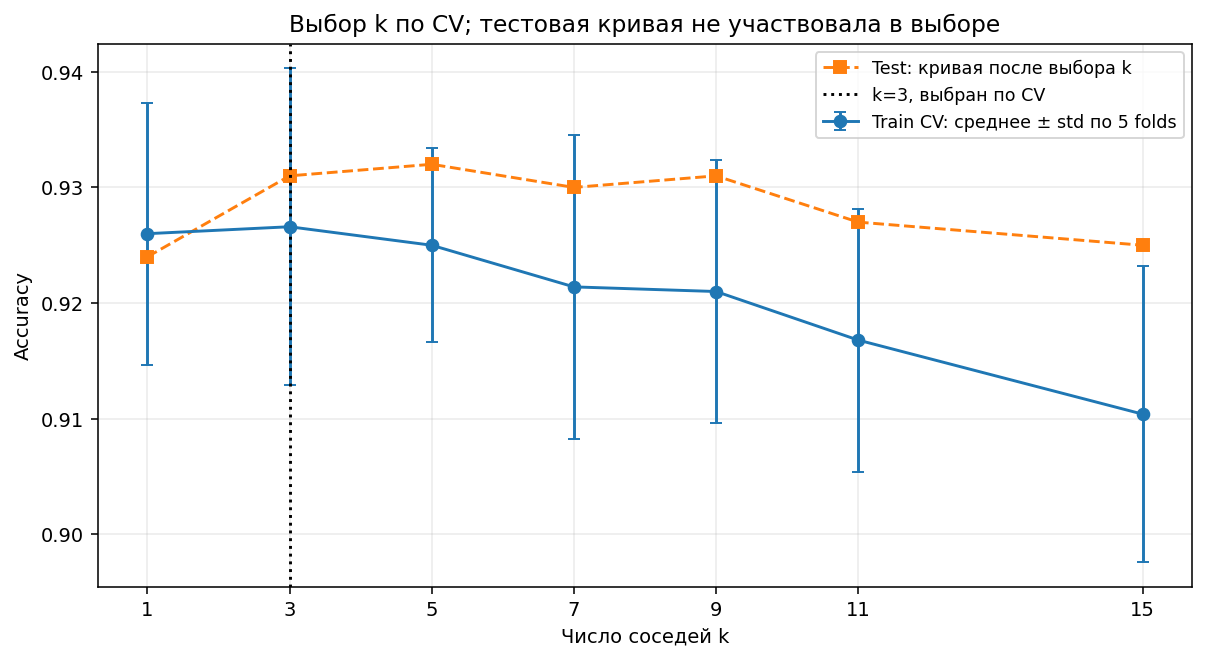

In [9]:
cv_folds = pd.read_csv(OUT / "knn_cv.csv")
display(cv_folds.pivot(index="k", columns="fold", values="accuracy"))
display(pd.DataFrame(summary["knn"]["cv_scores"]))
display(pd.read_csv(OUT / "knn_test_curve.csv"))
display(Image(filename=str(OUT / "figures/knn_accuracy.png")))

### 1.10–1.11. Итоговая модель kNN и вывод

После CV модель снова запоминает весь train. Выбранное k фиксируется перед тестированием.
Ниже повторяется предсказание подвыборки test, а полный итог и вывод рассчитываются
из фактических результатов.

In [10]:
best_k = int(summary["knn"]["best_k"])
knn.train(knn_features["train"], labels["train"])
selected_pred = knn.predict(knn_features["test"][:preview_n], k=best_k, batch_size=100)
print("Выбранное по CV k:", best_k)
print("Повторная проверка первых", preview_n, "test:", np.mean(selected_pred == labels["test"][:preview_n]))
knn_result = summary["knn"]
display(Markdown(
    f"**Вывод 1.11.** CV выбрала k={best_k}: средняя accuracy "
    f"{knn_result['cv_mean_accuracy']:.4f}, std {knn_result['cv_std_accuracy']:.4f}. "
    f"На полном test получено **{knn_result['test_accuracy']:.4f}**. "
    "Результат относится к расстоянию между пиксельными векторами и данным разбиениям; "
    "выбор k по тестовой кривой не выполнялся."
))

Выбранное по CV k: 3
Повторная проверка первых 100 test: 0.95


**Вывод 1.11.** CV выбрала k=3: средняя accuracy 0.9266, std 0.0137. На полном test получено **0.9310**. Результат относится к расстоянию между пиксельными векторами и данным разбиениям; выбор k по тестовой кривой не выполнялся.

## 3. Softmax-классификатор
### 3.1–3.3. Подготовка данных

Используются те же фиксированные train/validation/test. Изображения преобразуются в одномерные векторы и нормализуются. Среднее изображение вычисляется **только по train** и вычитается из train, validation и test. Затем добавляется дополнительный bias-признак со значением 1.

In [11]:
normalized_softmax = {split: flat_raw[split].astype(np.float64) / pixel_max for split in flat_raw}
softmax_mean_image = normalized_softmax["train"].mean(axis=0)
softmax_features = {
    split: np.column_stack((normalized_softmax[split] - softmax_mean_image,
                            np.ones(len(normalized_softmax[split]), dtype=np.float64)))
    for split in normalized_softmax
}
display(pd.DataFrame([
    {"split": split, "shape with bias": str(softmax_features[split].shape)} for split in softmax_features
]))

,split,shape with bias
0,train,"(5000, 785)"
1,val,"(1000, 785)"
2,test,"(1000, 785)"


### 3.4–3.6. Устойчивая softmax loss и проверка градиента

Из каждого вектора scores вычитается максимум. Loss вычисляется как
`log(sum(exp(shifted_scores))) − shifted_score[correct_class]`. Это предотвращает переполнение экспоненты. Используется L2-регуляризация. При почти нулевых весах loss близка к `log(C)`, где C — число классов. Аналитический градиент сравнивается с численным, а naive- и vectorized-реализации — друг с другом.

In [12]:
X_softmax_dev = softmax_features["train"][:32].astype(np.float64)
y_dev = labels["train"][:len(X_softmax_dev)]
W_check = np.random.default_rng(42).normal(scale=1e-4, size=(X_softmax_dev.shape[1], len(class_names)))
softmax_loop_loss, softmax_loop_grad = softmax_loss_naive(W_check, X_softmax_dev, y_dev, 5e-6)
softmax_vec_loss, softmax_vec_grad = softmax_loss_vectorized(W_check, X_softmax_dev, y_dev, 5e-6)
np.testing.assert_allclose(softmax_loop_loss, softmax_vec_loss, rtol=1e-10, atol=1e-12)
np.testing.assert_allclose(softmax_loop_grad, softmax_vec_grad, rtol=1e-10, atol=1e-12)
print("Softmax loss на мини-примере:", softmax_vec_loss, "; log(C):", np.log(len(class_names)))
print("Разность градиентов, Frobenius:", np.linalg.norm(softmax_loop_grad - softmax_vec_grad))
display(pd.DataFrame(summary["gradient_checks"]["softmax"]["finite_differences"]))
display(pd.DataFrame([summary["gradient_checks"]["softmax_sanity"]]))
for reg_check in (0.0, 50.0):
    _, softmax_analytic = softmax_loss_naive(W_check, X_softmax_dev, y_dev, reg_check)
    print("Sparse numerical gradient; softmax reg =", reg_check)
    softmax_sparse = grad_check_sparse(
        lambda weights: softmax_loss_naive(weights, X_softmax_dev, y_dev, reg_check)[0],
        W_check.copy(), softmax_analytic, num_checks=3
    )

Softmax loss на мини-примере: 2.3025242429588233 ; log(C): 2.302585092994046
Разность градиентов, Frobenius: 2.0474110266135267e-16


,reg,loss,max_relative_error,relative_l2_error,checked_parameters,h
0,0.0,2.303746,1.334557e-08,1.061735e-10,200,0.00001
1,50.0,2.314091,1.388678e-08,7.312131e-11,200,0.00001


,initial_loss,uniform_loss,absolute_difference
0,2.302537,2.302585,0.000049


Sparse numerical gradient; softmax reg = 0.0
numerical: 0.017136 analytic: 0.017136, relative error: 1.142346e-09
numerical: 0.000000 analytic: 0.000000, relative error: 0.000000e+00
numerical: -0.000067 analytic: -0.000067, relative error: 4.132944e-07
Sparse numerical gradient; softmax reg = 50.0
numerical: -0.002091 analytic: -0.002091, relative error: 3.114634e-09
numerical: -0.007090 analytic: -0.007090, relative error: 2.529206e-09
numerical: -0.014542 analytic: -0.014542, relative error: 6.180343e-10


### 3.7–3.8. SGD, baseline и тестовая оценка

Класс `Softmax` наследует тот же SGD и меняет функцию потерь. Сначала обучается
baseline с параметрами, зафиксированными до просмотра результатов. Его точность
приведена отдельно от модели, выбранной по validation. История содержит реальные
mini-batch loss, поэтому значения могут колебаться между соседними итерациями.

,learning_rate,reg,train_accuracy,val_accuracy,test_accuracy
Softmax baseline,0.01,0.001,0.8398,0.854,0.838


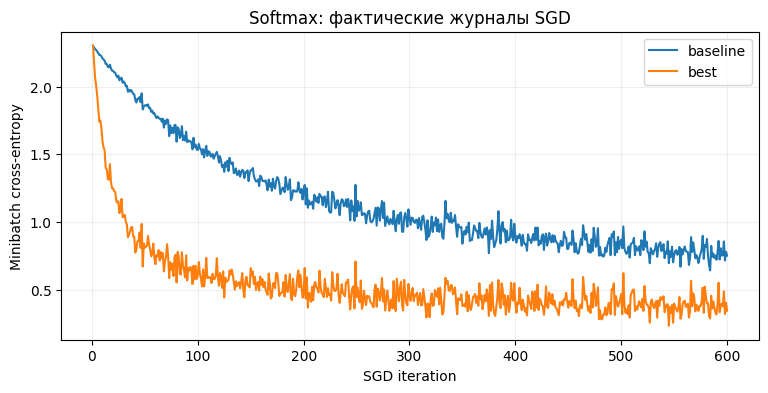

In [13]:
losses = pd.read_csv(OUT / "loss_history.csv")
display(pd.DataFrame([summary["softmax"]["baseline"]], index=["Softmax baseline"]))
fig, ax = plt.subplots()
for run, rows in losses[losses["classifier"] == "softmax"].groupby("run", sort=False):
    ax.plot(rows["iteration"], rows["loss"], label=run)
ax.set(xlabel="SGD iteration", ylabel="Minibatch cross-entropy", title="Softmax: фактические журналы SGD")
ax.legend()
plt.show()

### 3.9. Поиск параметров и проверка итоговой модели

Learning rate и регуляризация выбираются на validation. После выбора сохраняется
модель, обученная на train; train и validation не объединяются скрытно.
Test используется для финальной оценки выбранной модели, но не для выбора пары параметров.

In [14]:
display(pd.read_csv(OUT / "softmax_search.csv").sort_values("val_accuracy", ascending=False))
print("Лучшие параметры:", summary["softmax"]["best_params"])
with np.load(OUT / summary["softmax"]["checkpoint"], allow_pickle=False) as saved:
    softmax = Softmax(random_state=42)
    softmax.W = saved["W"].copy()
    saved_softmax_mean = saved["mean_image"].copy()
    softmax_scale = float(saved["scale"])
np.testing.assert_allclose(softmax_mean_image, saved_softmax_mean, rtol=1e-5, atol=1e-6)
softmax_test = flat_raw["test"].astype(np.float64) / softmax_scale - saved_softmax_mean
softmax_test = np.column_stack((softmax_test, np.ones(len(softmax_test), dtype=np.float64)))
softmax_predictions = softmax.predict(softmax_test)
softmax_test_accuracy = float(np.mean(softmax_predictions == labels["test"]))
assert np.isclose(softmax_test_accuracy, summary["softmax"]["test_accuracy"])
print("Повторно вычисленная полная test accuracy:", softmax_test_accuracy)

,learning_rate,reg,train_accuracy,val_accuracy
4,0.10,0.0001,0.9002,0.893
5,0.10,0.0010,0.8986,0.893
3,0.05,0.0010,0.8856,0.887
2,0.05,0.0001,0.8864,0.886
1,0.01,0.0010,0.8398,0.854
0,0.01,0.0001,0.8400,0.853


Лучшие параметры: {'learning_rate': 0.1, 'reg': 0.0001}
Повторно вычисленная полная test accuracy: 0.887


### 3.10. Вывод по softmax

Вывод строится из полученных чисел. Лучшее качество одной линейной модели
на данной выборке не означает её общего превосходства на других данных.

In [15]:
softmax_result = summary["softmax"]
softmax_delta = softmax_result["test_accuracy"] - summary["knn"]["test_accuracy"]
display(Markdown(
    f"**Вывод 3.10.** Для softmax выбраны {softmax_result['best_params']}. "
    f"Accuracy: train={softmax_result['train_accuracy']:.4f}, "
    f"validation={softmax_result['val_accuracy']:.4f}, test=**{softmax_test_accuracy:.4f}**. "
    f"На этом test-разбиении softmax отличается от kNN на {softmax_delta:+.4f}. "
    "Гиперпараметры выбирались по validation, test использовался только для итоговой оценки. "
    "Функция потерь и градиент проверены сравнением naive/vectorized и численным градиентом."
))

**Вывод 3.10.** Для softmax выбраны {'learning_rate': 0.1, 'reg': 0.0001}. Accuracy: train=0.9002, validation=0.8930, test=**0.8870**. На этом test-разбиении softmax отличается от kNN на -0.0440. Гиперпараметры выбирались по validation, test использовался только для итоговой оценки. Функция потерь и градиент проверены сравнением naive/vectorized и численным градиентом.

## Итоговое сравнение варианта 4

Сравниваются только два метода, требуемые вариантом 4: kNN и softmax.
Оба используют одно и то же test-разбиение MNIST, а параметры выбираются без использования test.

,train_accuracy,validation_accuracy,test_accuracy
model,,,
kNN,0.9674,0.938,0.931
Softmax,0.9002,0.893,0.887


На данном test-разбиении максимальная accuracy у **kNN**: 0.9310.

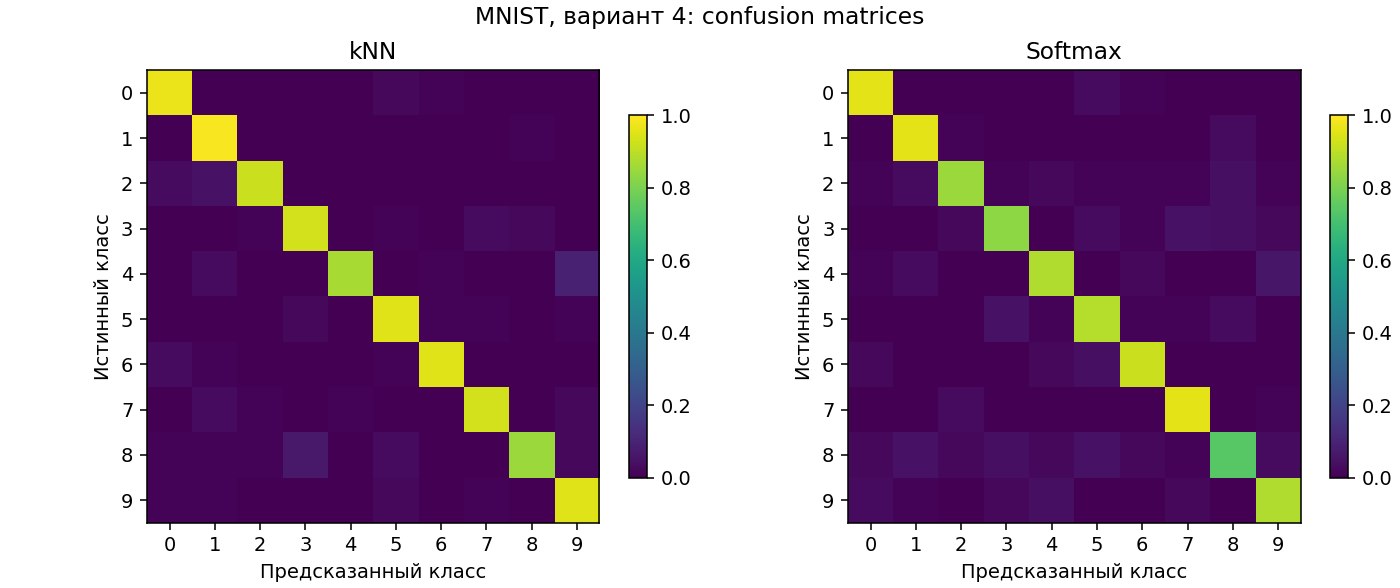

In [16]:
comparison = pd.DataFrame([
    {"model": name, "train_accuracy": summary[key]["train_accuracy"],
     "validation_accuracy": summary[key]["val_accuracy"], "test_accuracy": summary[key]["test_accuracy"]}
    for key, name in [("knn", "kNN"), ("softmax", "Softmax")]
]).set_index("model")
display(comparison)
best_model_name = comparison["test_accuracy"].idxmax()
display(Markdown(f"На данном test-разбиении максимальная accuracy у **{best_model_name}**: "
                 f"{comparison.loc[best_model_name, 'test_accuracy']:.4f}."))
display(Image(filename=str(OUT / "figures/confusion_matrices.png")))

## Воспроизведение и файлы реализации

- `scripts/classifiers/k_nearest_neighbor.py` — kNN и три реализации L2-расстояний.
- `scripts/classifiers/softmax.py` — naive/vectorized softmax loss и градиент.
- `scripts/classifiers/linear_classifier.py` — SGD и класс `Softmax`.
- `scripts/gradient_check.py` — численная проверка градиента.
- `outputs/mnist/` — CV, поиск гиперпараметров, модели и изображения.

Для полного пересчёта установите `RECOMPUTE=True` и выполните все ячейки.

In [17]:
print("Источник задания:", "https://github.com/JustHawker/AIT_Course_SamU_2026/blob/main/lab_1-2/assignment1.ipynb")
print("Набор:", DATASET, "; статус:", summary["status"])
print("Число train / validation / test:", *(len(labels[split]) for split in ("train", "val", "test")))
print("Seed:", summary["config"]["seed"])
print("Сохранённые результаты:", str(OUT.relative_to(ROOT)))

Источник задания: https://github.com/JustHawker/AIT_Course_SamU_2026/blob/main/lab_1-2/assignment1.ipynb
Набор: mnist ; статус: completed
Число train / validation / test: 5000 1000 1000
Seed: 42
Сохранённые результаты: outputs/mnist
